# MRP / 02 — Mean model on the training window: inference (§6) and walk-forward forecasts (§7), gate S

Protocol: [`MRP 001`](../../discussions/MNQ_Return_Prediction/001_claude_mrp01_preregistration.md). Uses `01/summary.json` for the primary scale (z if gate V passed, raw log returns × 10⁴ otherwise).

1. **In-sample inference** on 2020-01-01 – 2023-06-30: OLS, errors clustered by CME day; one Wald test per group A–G with Holm correction; Newey–West, Huber, both halves and the other scale as robustness; VIFs.
2. **Walk-forward** 2021-01-01 – 2023-06-30: M0 (zero), M1 (own lags), M2 (+ B, C, D, E), M3 (+ FX, interactions); R²_OOS, Clark–West, Brier, calibration, interval coverage.
3. **Gate S** and `02/summary.json` (03 refuses to run without it).

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("MRP_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("MRP_SYNTH_DIR") or tempfile.mkdtemp(prefix="mrp_")
    os.environ["MRP_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
OUT = Path("02"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("engine", P.MRP_VERSION, "| synthetic" if SYNTHETIC else "| real data", "| train", CFG.train)

if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    P.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.test[1], CFG)


engine 0.1.0 | real data | train (datetime.date(2020, 1, 1), datetime.date(2023, 6, 30))


In [2]:
V = json.loads(Path("01/summary.json").read_text())
SCALE = V["primary_scale"]
OTHER = "raw" if SCALE == "z" else "z"
print("gate V:", V["gate_V"]["pass"], "-> primary scale", SCALE)
grid, fx = P.load_inputs(CFG.train[1], CFG)
G = P.groups(CFG)
end_excl = CFG.train[1] + dt.timedelta(days=1)
X, y, meta = P.dataset_for(grid, fx, CFG.train[0], end_excl, CFG, SCALE)
w = P.in_window(meta, *CFG.train)
X, y, meta = X[w], y[w], meta[w]
print(X.shape, "targets,", meta["trade_date"].nunique(), "CME days")

gate V: False -> primary scale raw
(237183, 51) targets, 879 CME days


## 1. In-sample regression (clustered by CME day)

In [3]:
res = P.ols(X, y, clusters=meta["trade_date"].to_numpy())
res_nw = P.ols(X, y, nw_lags=CFG.nw_lags)
tab = res.table().join(res_nw.table()[["t"]].rename(columns={"t": "t_nw"}))
display(tab.round(4))
vif = P.vif(X); print("largest VIFs:"); display(vif.sort_values(ascending=False).head(8).round(2))

,coef,se,t,p,t_nw
const,0.0490,0.0222,2.2036,0.0278,2.1596
d_london,-0.0622,0.0381,-1.6332,0.1028,-1.5452
d_ny,0.0284,0.0610,0.4658,0.6415,0.4633
d_post,0.0409,0.0991,0.4124,0.6801,0.4213
z_l1,-0.0080,0.0084,-0.9588,0.3379,-0.9037
z_l2,-0.0175,0.0058,-3.0047,0.0027,-3.1131
z_l3,0.0051,0.0052,0.9773,0.3287,0.9119
z_l4,0.0088,0.0046,1.9289,0.0541,1.7338
z_l5,-0.0034,0.0053,-0.6360,0.5250,-0.6380
z_l6,-0.0032,0.0053,-0.6115,0.5410,-0.6268


largest VIFs:


ny_x_AUDUSD_l1    8.45
ny_x_NZDUSD_l1    7.88
AUDUSD_l1         6.56
NZDUSD_l1         5.99
ny_x_EURUSD_l1    5.13
AUDUSD_l2         4.85
AUDUSD_l3         4.80
EURUSD_l1         4.52
Name: vif, dtype: float64

In [4]:
wald = {k: P.wald(res, c) for k, c in G.items()}
wald_nw = {k: P.wald(res_nw, c) for k, c in G.items()}
h = P.holm({k: v["p"] for k, v in wald.items()})
h["F"] = [wald[k]["F"] for k in h.index]; h["q"] = [wald[k]["q"] for k in h.index]
h["p_nw"] = [wald_nw[k]["p"] for k in h.index]
display(h.round(5))

,p,p_holm,reject,F,q,p_nw
A_own_lags,0.02598,0.18189,False,1.94887,12,0.12066
F_fx,0.03174,0.19047,False,1.65902,21,0.10179
E_same_slot_yday,0.13407,0.67033,False,2.24893,1,0.17370
D_prev_day,0.28287,1.00000,False,1.15464,1,0.36664
B_large_move,0.30667,1.00000,False,1.04618,1,0.35156
G_ny_interactions,0.76688,1.00000,False,0.61369,8,0.77945
C_sessions,0.90620,1.00000,False,0.18562,3,0.93070


## 2. Robustness: Huber, halves, other scale

In [5]:
hub = P.huber(X, y)
halves = []
for a, b in CFG.halves:
    m = P.in_window(meta, a, b)
    halves.append(P.ols(X[m], y[m], clusters=meta["trade_date"].to_numpy()[m]))
Xo, yo, mo = P.dataset_for(grid, fx, CFG.train[0], end_excl, CFG, OTHER)
wo = P.in_window(mo, *CFG.train)
res_o = P.ols(Xo[wo], yo[wo], clusters=mo["trade_date"].to_numpy()[wo])
rob = pd.DataFrame({"coef": res.beta, "huber": hub["coef"].to_numpy(), "half1": halves[0].beta, "half2": halves[1].beta,
                    f"coef_{OTHER}": res_o.beta}, index=res.names)
display(rob.round(4))

def robust(cols):
    """Signs agree across main fit, Huber and both halves, on the group's coefficients with |t| >= 2 in the main
    fit (the largest |t| if none reaches 2)."""
    t = tab.loc[cols, "t"].abs()
    key = list(t[t >= 2].index) or [t.idxmax()]
    s = np.sign(rob.loc[key, ["coef", "huber", "half1", "half2"]])
    return bool((s.nunique(axis=1) == 1).all())

groups_out = {}
for k, cols in G.items():
    groups_out[k] = {"F": wald[k]["F"], "p": wald[k]["p"], "p_holm": float(h.loc[k, "p_holm"]),
                     "reject_holm": bool(h.loc[k, "reject"]), "p_nw": wald_nw[k]["p"],
                     "p_other_scale": P.wald(res_o, cols)["p"], "signs_robust": robust(cols),
                     "coefs": {c: float(rob.loc[c, "coef"]) for c in cols}}
display(pd.DataFrame(groups_out).T[["F", "p", "p_holm", "reject_holm", "p_nw", "p_other_scale", "signs_robust"]])

,coef,huber,half1,half2,coef_z
const,0.0490,0.0663,0.0936,0.0007,0.0063
d_london,-0.0622,-0.0266,-0.0804,-0.0467,-0.0078
d_ny,0.0284,0.2461,-0.0203,0.0768,0.0003
d_post,0.0409,0.1254,-0.0521,0.1241,0.0254
z_l1,-0.0080,-0.0246,-0.0016,-0.0145,-0.0102
z_l2,-0.0175,-0.0265,-0.0213,-0.0119,-0.0086
z_l3,0.0051,-0.0063,0.0134,-0.0030,0.0016
z_l4,0.0088,-0.0055,0.0095,0.0075,-0.0001
z_l5,-0.0034,-0.0059,-0.0092,0.0029,0.0043
z_l6,-0.0032,-0.0068,-0.0123,0.0069,0.0015


,F,p,p_holm,reject_holm,p_nw,p_other_scale,signs_robust
A_own_lags,1.948869,0.025984,0.181889,False,0.120663,0.000816,True
B_large_move,1.046176,0.306671,1.0,False,0.351556,0.017084,True
C_sessions,0.185624,0.906199,1.0,False,0.930695,0.019862,False
D_prev_day,1.154642,0.282875,1.0,False,0.366638,0.102112,False
E_same_slot_yday,2.248929,0.134066,0.670332,False,0.1737,0.216728,False
F_fx,1.659022,0.031745,0.190468,False,0.101794,0.104792,True
G_ny_interactions,0.61369,0.766881,1.0,False,0.779451,0.066189,False


## 3. Hypotheses (MRP 001 §5)

- **A** lag 1 ≤ 0 and small; lags 2–12 ≈ 0 · **B** mom3 > 0 (Iván) · **D** previous CME day strongly ≠ 0 (Iván, no sign) · **F** FX = 0 (Iván).

In [6]:
def coef(c): return float(rob.loc[c, "coef"])
hyp = {
    "A: lag1 <= 0 and |lag1| small": {"lag1": coef("z_l1"), "group_reject": groups_out["A_own_lags"]["reject_holm"]},
    "B: mom3 > 0": {"coef": coef("mom3"), "reject": groups_out["B_large_move"]["reject_holm"],
                    "supported": groups_out["B_large_move"]["reject_holm"] and coef("mom3") > 0 and groups_out["B_large_move"]["signs_robust"]},
    "D: prev_day != 0": {"coef": coef("prev_day"), "supported": groups_out["D_prev_day"]["reject_holm"] and groups_out["D_prev_day"]["signs_robust"]},
    "F: FX = 0": {"reject": groups_out["F_fx"]["reject_holm"], "supported": not groups_out["F_fx"]["reject_holm"]},
}
display(pd.DataFrame(hyp).T)

,lag1,group_reject,coef,reject,supported
A: lag1 <= 0 and |lag1| small,-0.008018,False,NaN,NaN,NaN
B: mom3 > 0,NaN,NaN,0.009077,False,False
D: prev_day != 0,NaN,NaN,-0.000408,NaN,False
F: FX = 0,NaN,NaN,NaN,False,True


## 4. Walk-forward forecasts 2021-01-01 – 2023-06-30

In [7]:
dss = {r: P.dataset_for(grid, fx, CFG.train[0], r, CFG, SCALE) for r in CFG.refits_train}
fc = P.walk_forward(dss, CFG.refits_train, CFG.train[1], CFG.train[0], CFG)
edges = list(CFG.refits_train) + [CFG.train[1] + dt.timedelta(days=1)]
td = fc["trade_date"].to_numpy()
periods = {"all": np.ones(len(fc), bool)}
for a, b in zip(edges[:-1], edges[1:]):
    periods[f"{a}..{b - dt.timedelta(days=1)}"] = (td >= a) & (td < b)
rep = P.forecast_report(fc, periods)
flat = pd.DataFrame({k: {m: (v["p_one_sided"] if isinstance(v, dict) else v) for m, v in r.items()} for k, r in rep.items()})
display(flat)

,all,2021-01-01..2021-12-31,2022-01-01..2022-12-31,2023-01-01..2023-06-30
n,168433.000000,69613.000000,64070.000000,34750.000000
days,622.000000,258.000000,236.000000,128.000000
r2_M1_vs_M0,-0.000811,-0.000439,-0.000850,-0.001269
cw_M1_vs_M0,0.275377,0.112329,0.400750,0.888053
brier_M1,0.251242,0.250574,0.252309,0.250596
r2_M2_vs_M0,-0.001179,-0.000552,-0.001358,-0.001446
cw_M2_vs_M0,0.241031,0.058248,0.462462,0.893942
brier_M2,0.252032,0.250962,0.253887,0.250727
r2_M3_vs_M0,-0.002179,-0.002704,-0.001837,-0.002807
cw_M3_vs_M0,0.125627,0.055234,0.190020,0.950783


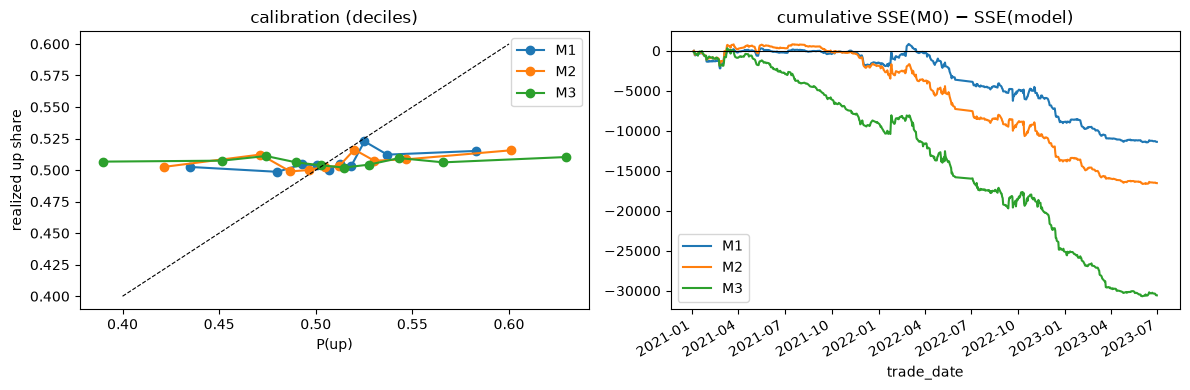

,M1,M2,M3
cover_50,0.036507,0.036638,0.036329
cover_90,0.126371,0.126852,0.125284


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m in ("M1", "M2", "M3"):
    cal = P.calibration(fc[f"pup_{m}"].to_numpy(), fc["ret"].to_numpy())
    ax[0].plot(cal["p_mean"], cal["up_rate"], "o-", label=m)
ax[0].plot([0.4, 0.6], [0.4, 0.6], "k--", lw=.8); ax[0].set_xlabel("P(up)"); ax[0].set_ylabel("realized up share"); ax[0].legend()
ax[0].set_title("calibration (deciles)")
for m in ("M1", "M2", "M3"):
    e = (fc["y"] - fc["mu_M0"]) ** 2 - (fc["y"] - fc[f"mu_{m}"]) ** 2
    e.groupby(pd.to_datetime(fc["trade_date"])).sum().cumsum().plot(ax=ax[1], label=m)
ax[1].axhline(0, color="k", lw=.8); ax[1].set_title("cumulative SSE(M0) − SSE(model)"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "forecasts.png", dpi=110); plt.show()
cover = {m: P.interval_coverage(fc, m) for m in ("M1", "M2", "M3")}
display(pd.DataFrame(cover))

## 5. Gate S

In [9]:
sub = [k for k in periods if k != "all"]
best = max(("M1", "M2", "M3"), key=lambda m: rep["all"][f"r2_{m}_vs_M0"])
r2_best = rep["all"][f"r2_{best}_vs_M0"]
cw_best = rep["all"][f"cw_{best}_vs_M0"]["p_one_sided"]
pos_periods = sum(rep[k][f"r2_{best}_vs_M0"] > 0 for k in sub)
S = bool(r2_best > 0 and cw_best < 0.05 and pos_periods >= 2)
S_fx = bool(rep["all"]["cw_M3_vs_M2"]["p_one_sided"] < 0.05)
print(f"best model {best}: R2_OOS {r2_best:.5f}, CW p {cw_best:.4f}, positive in {pos_periods}/{len(sub)} periods -> S {'PASS' if S else 'FAIL'}")
print(f"FX increment (M3 vs M2): R2 {rep['all']['r2_M3_vs_M2']:.5f}, CW p {rep['all']['cw_M3_vs_M2']['p_one_sided']:.4f} -> {'PASS' if S_fx else 'FAIL'}")
summary = {"engine": P.MRP_VERSION, "synthetic": SYNTHETIC, "scale": SCALE, "gate_V": V["gate_V"]["pass"],
           "groups": groups_out, "hypotheses": hyp, "forecast": rep, "coverage": cover,
           "gate_S": {"pass": S, "best_model": best, "r2": r2_best, "cw_p": cw_best, "positive_periods": pos_periods,
                      "fx_increment_pass": S_fx}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=lambda o: bool(o) if isinstance(o, np.bool_) else float(o)))
tab.to_csv(OUT / "coefficients.csv"); rob.to_csv(OUT / "robustness.csv")

best model M1: R2_OOS -0.00081, CW p 0.2754, positive in 0/3 periods -> S FAIL
FX increment (M3 vs M2): R2 -0.00100, CW p 0.1267 -> FAIL
